# Variational Classifier — Iris Dataset


## Librerias

In [13]:
# 1. Import all libraries
import pandas as pd
import time
import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as np
from pennylane.optimize import NesterovMomentumOptimizer
from sklearn import datasets
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

np.random.seed(123)


## Data

In [14]:
data = pd.DataFrame(datasets.load_iris().data, columns=datasets.load_iris().feature_names)
data['target'] = datasets.load_iris().target
data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [15]:
data.target.unique()

array([0, 1, 2])

## Data Preparation

In [16]:
n_qubits = 4

X = data.drop(columns='target')
y = data['target']

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=123, stratify=y
)

print(f"Custom Dataset Loaded: Train={len(X_train)}, Test={len(X_test)}")

# Normalize to [0, π]
minmax = MinMaxScaler(feature_range=(0, np.pi))
X_train = minmax.fit_transform(np.array(X_train, dtype=float))
X_test = minmax.transform(np.array(X_test, dtype=float))
X_test = np.clip(X_test, 0, np.pi)
y_train = np.array(y_train)
y_test = np.array(y_test)

print(f"Final shapes -> Train: {X_train.shape}, Test: {X_test.shape}")


Custom Dataset Loaded: Train=90, Test=60
Final shapes -> Train: (90, 4), Test: (60, 4)


## Variational Classifier

In [17]:
dev = qml.device("default.qubit")

### Variational Data Prep

In [18]:
# Use the stratified train split prepared above
X = np.array(X_train, dtype=float)
y = np.array(y_train, dtype=int)


In [19]:
def layer(layer_weights):
    for wire in range(4):
        qml.Rot(*layer_weights[wire], wires=wire)
    for wires in ([0, 1], [1, 2], [2, 3], [3, 0]):
        qml.CNOT(wires=wires)

In [20]:
def state_preparation(x):
    for i in range(4):
        qml.RY(x[i], wires=i)

In [21]:
@qml.qnode(dev)
def circuit(weights, x):
    state_preparation(x)
    for layer_weights in weights:
        layer(layer_weights)
    return [
        qml.expval(qml.PauliZ(0)),
        qml.expval(qml.PauliZ(1)),
        qml.expval(qml.PauliZ(2)),
    ]

def variational_classifier(weights, bias, x):
    out = qml.math.stack(circuit(weights, x))
    return out + bias

def cost(weights, bias, X, Y):
    predictions = qml.math.stack(
        [variational_classifier(weights, bias, x) for x in X]
    )
    Y = np.array(Y, dtype=int)
    targets = np.eye(3)[Y]
    return qml.math.mean((predictions - targets) ** 2)

In [22]:
# --- Tiempo de entrenamiento ---
np.random.seed(123)
weights = 0.01 * np.random.randn(2, 4, 3, requires_grad=True)
bias = np.zeros(3, requires_grad=True)
opt = NesterovMomentumOptimizer(0.1)
batch_size = 5

start = time.time()
for it in range(100):
    batch_index = np.random.randint(0, len(X), (batch_size,))
    X_batch = X[batch_index]
    Y_batch = y[batch_index]
    weights, bias = opt.step(cost, weights, bias, X=X_batch, Y=Y_batch)

    predictions = [np.argmax(variational_classifier(weights, bias, x)) for x in X]
    current_cost = cost(weights, bias, X, y)
    acc = np.mean(np.array(predictions) == np.array(y))
    print(f"Iter: {it+1:4d} | Cost: {current_cost:0.7f} | Accuracy: {acc:0.7f}")
train_time = time.time() - start
print(f"\nTraining time: {train_time:.4f} s")


Iter:    1 | Cost: 0.5186454 | Accuracy: 0.1888889
Iter:    2 | Cost: 0.4875620 | Accuracy: 0.1222222
Iter:    3 | Cost: 0.4475936 | Accuracy: 0.1444444
Iter:    4 | Cost: 0.4177394 | Accuracy: 0.2000000
Iter:    5 | Cost: 0.3880286 | Accuracy: 0.2111111
Iter:    6 | Cost: 0.3639677 | Accuracy: 0.2555556
Iter:    7 | Cost: 0.3412819 | Accuracy: 0.2888889
Iter:    8 | Cost: 0.3259176 | Accuracy: 0.3333333
Iter:    9 | Cost: 0.3209314 | Accuracy: 0.3888889
Iter:   10 | Cost: 0.3154031 | Accuracy: 0.5333333
Iter:   11 | Cost: 0.3147352 | Accuracy: 0.6111111
Iter:   12 | Cost: 0.3035595 | Accuracy: 0.6222222
Iter:   13 | Cost: 0.2735370 | Accuracy: 0.6222222
Iter:   14 | Cost: 0.2413073 | Accuracy: 0.6222222
Iter:   15 | Cost: 0.2111036 | Accuracy: 0.6222222
Iter:   16 | Cost: 0.1879714 | Accuracy: 0.6222222
Iter:   17 | Cost: 0.1728888 | Accuracy: 0.6444444
Iter:   18 | Cost: 0.1707938 | Accuracy: 0.6777778
Iter:   19 | Cost: 0.1789241 | Accuracy: 0.7000000
Iter:   20 | Cost: 0.1854709 | 

In [23]:
# Predicción + métricas train vs test
def predict(weights, bias, X_data):
    return np.array([
        np.argmax(variational_classifier(weights, bias, x))
        for x in X_data
    ])

def evaluate_split(weights, bias, X_data, y_data):
    preds = predict(weights, bias, X_data)
    y_true = np.array(y_data).astype(int)
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, average="macro", zero_division=0)
    rec = recall_score(y_true, preds, average="macro", zero_division=0)
    f1 = f1_score(y_true, preds, average="macro", zero_division=0)
    return acc, prec, rec, f1, preds

start = time.time()
y_test_pred = predict(weights, bias, X_test)
infer_time = time.time() - start

vqc_acc_tr, vqc_prec_tr, vqc_rec_tr, vqc_f1_tr, _ = evaluate_split(weights, bias, X, y)
vqc_acc, vqc_prec, vqc_rec, vqc_f1, y_test_pred = evaluate_split(weights, bias, X_test, y_test)

print("\n=== Train vs Test ===")
print(
    f"VQC Train - Acc: {vqc_acc_tr:.4f} | Prec: {vqc_prec_tr:.4f} | Rec: {vqc_rec_tr:.4f} | "
    f"F1: {vqc_f1_tr:.4f}"
)
print(
    f"VQC Test  - Acc: {vqc_acc:.4f} | Prec: {vqc_prec:.4f} | Rec: {vqc_rec:.4f} | "
    f"F1: {vqc_f1:.4f}"
)
print(f"Inference time: {infer_time:.4f} s")
print(f"Training time:  {train_time:.4f} s")



=== Train vs Test ===
VQC Train - Acc: 0.9444 | Prec: 0.9462 | Rec: 0.9444 | F1: 0.9448
VQC Test  - Acc: 0.9500 | Prec: 0.9507 | Rec: 0.9500 | F1: 0.9500
Inference time: 0.1517 s
Training time:  48.9827 s


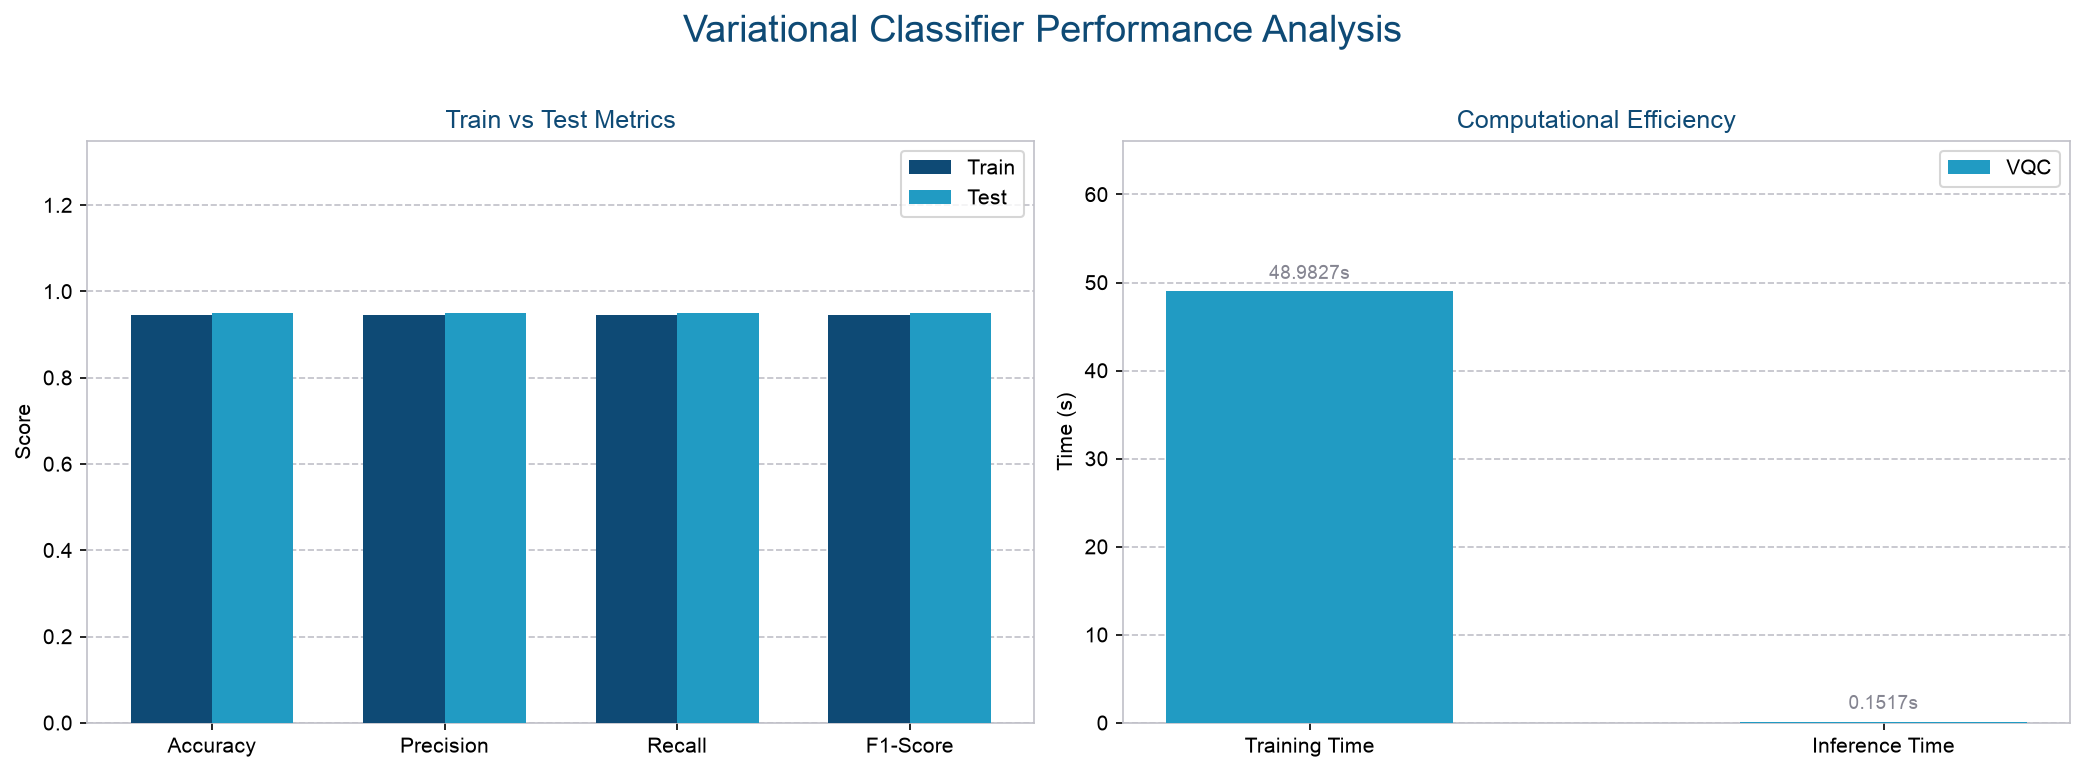

In [24]:
# Visualización train vs test (paleta UNIR)
plt.rcParams.update({
    'font.sans-serif': ['Arial'],
    'axes.edgecolor': '#C0C0C8',
    'grid.color': '#C0C0C8',
    'grid.linestyle': '--'
})

train_color = '#0E4A75'
test_color = '#219BC3'
unir_gris = '#858591'

fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle('Variational Classifier Performance Analysis', fontsize=18, y=1.02, color='#0E4A75')

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
train_vals = [vqc_acc_tr, vqc_prec_tr, vqc_rec_tr, vqc_f1_tr]
test_vals = [vqc_acc, vqc_prec, vqc_rec, vqc_f1]
x = np.arange(len(metrics))
width = 0.35

for i in range(len(metrics)):
    axs[0].bar(x[i] - width/2, train_vals[i], width, color=train_color,
               label='Train' if i == 0 else '', zorder=3)
    axs[0].bar(x[i] + width/2, test_vals[i], width, color=test_color,
               label='Test' if i == 0 else '', zorder=3)

axs[0].set_ylabel('Score')
axs[0].set_title('Train vs Test Metrics', color='#0E4A75')
axs[0].set_xticks(x)
axs[0].set_xticklabels(metrics)
axs[0].set_ylim(0, 1.35)
axs[0].legend(loc='upper right')
axs[0].grid(axis='y', zorder=0)

eff_labels = ['Training Time', 'Inference Time']
vqc_eff = [train_time, infer_time]
x_eff = np.arange(len(eff_labels))
axs[1].bar(x_eff, vqc_eff, 0.5, color=test_color, label='VQC', zorder=3)
axs[1].set_xticks(x_eff)
axs[1].set_xticklabels(eff_labels)
axs[1].set_ylabel('Time (s)')
axs[1].set_title('Computational Efficiency', color='#0E4A75')
max_time = max(vqc_eff)
axs[1].set_ylim(0, max_time * 1.35 if max_time > 0 else 1)
axs[1].legend(loc='upper right')
axs[1].grid(axis='y', zorder=0)
offset = max_time * 0.02 if max_time > 0 else 0.02
for i in range(2):
    axs[1].text(x_eff[i], vqc_eff[i] + offset, f'{vqc_eff[i]:.4f}s',
                ha='center', va='bottom', fontsize=9, color=unir_gris)

plt.tight_layout()
plt.show()
